# Lab 1: Regression Models: Predicting Flight Ticket Prices
**DA380A Machine Learning** · Dataset 5: *AirTravel* · Author: San Mirza, Mateusz Plizga, Johnny Chang

## Problem and target variable
The AirTravel dataset contains about 300,000 one-way domestic flights in India between six large cities
(Delhi, Mumbai, Bangalore, Kolkata, Hyderabad and Chennai), observed for departures between 11 February and
31 March 2022. For each flight we know the airline, route, departure and arrival time, duration, number of stops,
travel class and **ticket price**.

**Target:** `price`, the ticket price in Indian rupees (INR) for a single seat on that flight, as it was
offered on a booking site when the data was collected. A good model tells a traveller roughly what a trip should cost
(and how much booking earlier saves), and shows which factors drive airline pricing.

## Workflow in this notebook
1. Explore and understand the dataset
2. Prepare the data (feature selection, encoding, scaling)
3. Split into training (80 %) and test (20 %) sets
4. Build two regression models: **Linear Regression (Ridge)** and **Random Forest**
5. Evaluate both on the test set (MAE, RMSE, R²)
6. Tune hyperparameters with 5-fold cross-validation on the training data
7. Interpret the models (feature importance), compare them and recommend one

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, PolynomialFeatures, StandardScaler

RANDOM_STATE = 42  # fixed seed so every result in the notebook is reproducible
DATA_DIR = Path("data/dataset5-AirTravel")
FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

# Chart styling: one colour per travel class / model, used consistently in every figure
BLUE, ORANGE = "#2a78d6", "#eb6834"
CLASS_COLORS = {"Business": BLUE, "Economy": ORANGE}
MODEL_COLORS = {"Linear (Ridge)": BLUE, "Random Forest": ORANGE}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 100, "savefig.dpi": 150, "lines.linewidth": 2, "font.size": 10,
})


def show(table, decimals=1):
    """Display a results table: R² with 4 decimals, everything else with thousands separators."""
    fmt = {c: ("{:.4f}" if "R2" in str(c) or "R²" in str(c) else f"{{:,.{decimals}f}}")
           for c in table.select_dtypes("number").columns}
    return table.style.format(fmt)


def save(fig, name):
    """Save a figure to figures/ so it can be reused in the PDF report."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## 1. Explore and understand the dataset
### 1.1 Load the data
The dataset is delivered as two files with identical columns: `business.csv` and `economy.csv`.
The travel class is only encoded in the file name, so we add it as a `class` column and combine the two files.

In [2]:
business = pd.read_csv(DATA_DIR / "business.csv")
economy = pd.read_csv(DATA_DIR / "economy.csv")
business["class"] = "Business"
economy["class"] = "Economy"

raw = pd.concat([business, economy], ignore_index=True)
print("business:", business.shape, "| economy:", economy.shape, "| combined:", raw.shape)
raw.head()

business: (93487, 12) | economy: (206774, 12) | combined: (300261, 12)


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price,class
0,11-02-2022,Air India,AI,868,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612",Business
1,11-02-2022,Air India,AI,624,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612",Business
2,11-02-2022,Air India,AI,531,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220",Business
3,11-02-2022,Air India,AI,839,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450",Business
4,11-02-2022,Air India,AI,544,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690",Business


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 300261 entries, 0 to 300260
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   date        300261 non-null  str  
 1   airline     300261 non-null  str  
 2   ch_code     300261 non-null  str  
 3   num_code    300261 non-null  int64
 4   dep_time    300261 non-null  str  
 5   from        300261 non-null  str  
 6   time_taken  300261 non-null  str  
 7   stop        300261 non-null  str  
 8   arr_time    300261 non-null  str  
 9   to          300261 non-null  str  
 10  price       300261 non-null  str  
 11  class       300261 non-null  str  
dtypes: int64(1), str(11)
memory usage: 27.5 MB


In [4]:
# Descriptive statistics for all columns (numbers and text)
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,300261,49,07-03-2022,6633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airline,300261,8,Vistara,127859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ch_code,300261,8,UK,127859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_code,"300,261.00",NaN,NaN,NaN,"1,417.77","1,974.51",101.00,637.00,818.00,927.00,"9,991.00"
dep_time,300261,251,07:00,8760,NaN,NaN,NaN,NaN,NaN,NaN,NaN
from,300261,6,Delhi,61345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_taken,300261,483,02h 10m,4242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stop,300261,40,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,243603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arr_time,300261,266,19:55,9194,NaN,NaN,NaN,NaN,NaN,NaN,NaN
to,300261,6,Mumbai,59109,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2 Data quality checks
We check for missing values, duplicated rows and columns whose content does not match their data type.

In [5]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print("\nDuplicated rows:", raw.duplicated().sum())

Missing values per column:
date          0
airline       0
ch_code       0
num_code      0
dep_time      0
from          0
time_taken    0
stop          0
arr_time      0
to            0
price         0
class         0

Duplicated rows: 2


In [6]:
# Several numeric quantities are stored as text and need parsing
print("price examples:     ", raw["price"].sample(5, random_state=RANDOM_STATE).tolist())
print("time_taken examples:", raw["time_taken"].sample(5, random_state=RANDOM_STATE).tolist())

# 'stop' contains hidden tabs/newlines and, for some flights, the name of the stop-over airport
print("\nMost common raw 'stop' values:")
print(raw["stop"].map(repr).value_counts().head(5).to_string())

# A handful of durations do not follow the 'XXh YYm' pattern
odd = raw.loc[~raw["time_taken"].str.fullmatch(r"\d+h \d+m"), "time_taken"]
print("\nDurations with an invalid format:", odd.str.contains(r"\.").sum(), "->",
      odd[odd.str.contains(r"\.")].unique())

print("\nFlights per airline:")
print(raw["airline"].value_counts().to_string())

price examples:      ['2,074', '10,260', '32,347', '51,707', '41,269']
time_taken examples: ['07h 30m', '17h 50m', '24h 50m', '25h 30m', '20h 20m']

Most common raw 'stop' values:
stop
'1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t'           243603
'non-stop '                                                             36044
'2+-stop'                                                               13288
'1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia IXU\n\t\t\t\t\t\t\t\t\t\t\t\t'      1839
'1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia IDR\n\t\t\t\t\t\t\t\t\t\t\t\t'      1398

Durations with an invalid format: 4 -> <StringArray>
['1.03h m', '1.02h m', '1.01h m']
Length: 3, dtype: str

Flights per airline:
airline
Vistara      127859
Air India     80894
Indigo        43120
GO FIRST      23177
AirAsia       16098
SpiceJet       9011
StarAir          61
Trujet           41


### 1.3 Cleaning and feature engineering
The issues found above are fixed before the visual exploration:

| Raw column | Problem | New column |
|---|---|---|
| `price` | text with a thousands separator (`"25,612"`) | `price` as an integer (target) |
| `stop` | text with tabs, newlines and stop-over airport names | `stops` = 0, 1 or 2 (2 means "2 or more") |
| `time_taken` | text such as `"02h 10m"`; 4 rows are malformed (`"1.03h m"`) | `duration_min` (minutes); malformed rows removed |
| `date` | only spans seven weeks, so the raw date itself is not useful | `days_left` (days between data collection on 10 Feb 2022 and departure) and `weekday` |
| `dep_time`, `arr_time` | clock times | `dep_period`, `arr_period` (part of the day) |

In [7]:
df = raw.copy()

# Target: "25,612" -> 25612
df["price"] = df["price"].str.replace(",", "", regex=False).astype(int)

# Number of stops: keep only the first word ("non-stop" / "1-stop" / "2+-stop")
stop_text = df["stop"].str.strip().str.split("\n").str[0].str.strip()
df["stops"] = stop_text.map({"non-stop": 0, "1-stop": 1, "2+-stop": 2})

# Duration "02h 10m" -> 130 minutes (invalid formats become NaN)
hours_minutes = df["time_taken"].str.extract(r"^(\d+)h (\d+)m$").astype(float)
df["duration_min"] = hours_minutes[0] * 60 + hours_minutes[1]

# Booking lead time: prices were collected on 10 Feb 2022 for flights 1-49 days ahead
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y")
df["days_left"] = (df["date"] - pd.Timestamp("2022-02-10")).dt.days
df["weekday"] = df["date"].dt.day_name()

# Departure / arrival clock time -> part of the day
PERIODS = ["Night (00-05)", "Morning (06-11)", "Afternoon (12-16)", "Evening (17-20)", "Late evening (21-23)"]


def part_of_day(clock):
    hour = pd.to_datetime(clock, format="%H:%M").dt.hour
    return pd.cut(hour, bins=[-1, 5, 11, 16, 20, 23], labels=PERIODS).astype(str)


df["dep_period"] = part_of_day(df["dep_time"])
df["arr_period"] = part_of_day(df["arr_time"])

# Remove exact duplicates and rows whose duration could not be parsed
n_before = len(df)
df = df.drop_duplicates(subset=raw.columns.tolist())
df = df.dropna(subset=["stops", "duration_min"]).reset_index(drop=True)
df["stops"] = df["stops"].astype(int)
print(f"Removed {n_before - len(df)} rows -> {len(df):,} rows remain")
print("Missing values after cleaning:", df.isna().sum().sum())

Removed 6 rows -> 300,255 rows remain
Missing values after cleaning: 0


In [8]:
# Unusual values: look at the range of the numeric columns per class
df.groupby("class")[["price", "duration_min", "stops", "days_left"]].describe().T

class                Business    Economy
price        count  93,487.00 206,768.00
             mean   52,540.08   6,571.20
             std    12,969.31   3,743.47
             min    12,000.00   1,105.00
             25%    45,185.00   4,173.00
             50%    53,164.00   5,772.00
             75%    60,396.00   7,746.00
             max   123,071.00  42,349.00
duration_min count  93,487.00 206,768.00
             mean      822.25     692.75
             std       411.15     434.53
             min        60.00      50.00
             25%       530.00     375.00
             50%       785.00     610.00
             75%     1,070.00     915.00
             max     2,865.00   2,990.00
stops        count  93,487.00 206,768.00
             mean        0.92       0.92
             std         0.30       0.43
             min         0.00       0.00
             25%         1.00       1.00
             50%         1.00       1.00
             75%         1.00       1.00
             max         2.00       2.00
days_left    count  93,487.00 206,768.00
             mean       25.74      26.12
             std        13.63      13.53
             min         1.00       1.00
             25%        14.00      15.00
             50%        26.00      26.00
             75%        38.00      38.00
             max        49.00      49.00

In [9]:
# How extreme are the longest flights and highest prices?
q = df.groupby("class")["price"].quantile([0.99]).unstack()
print("99th percentile of price per class:\n", q.to_string())
print("\nFlights longer than 24 hours:", (df["duration_min"] > 24 * 60).sum(),
      f"({(df['duration_min'] > 24 * 60).mean():.2%} of rows)")
print("Longest duration (hours):", df["duration_min"].max() / 60)

99th percentile of price per class:
               0.99
class             
Business 84,896.00
Economy  19,661.64

Flights longer than 24 hours: 27671 (9.22% of rows)
Longest duration (hours): 49.833333333333336


### 1.4 Visual exploration

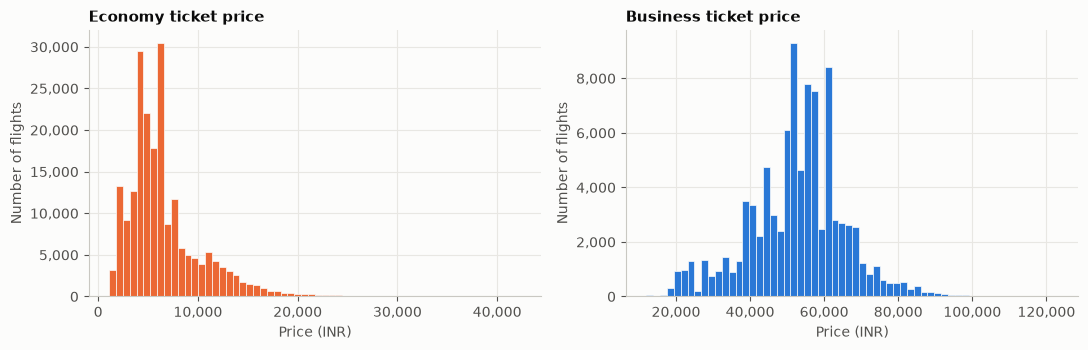

In [10]:
# Target distribution: business and economy prices live on very different scales,
# so each class gets its own panel (two separate x-axes instead of one squashed one)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, cls in zip(axes, ["Economy", "Business"]):
    ax.hist(df.loc[df["class"] == cls, "price"], bins=60, color=CLASS_COLORS[cls], edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_title(f"{cls} ticket price")
    ax.set_xlabel("Price (INR)")
    ax.set_ylabel("Number of flights")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
save(fig, "fig01_price_distribution")
plt.show()

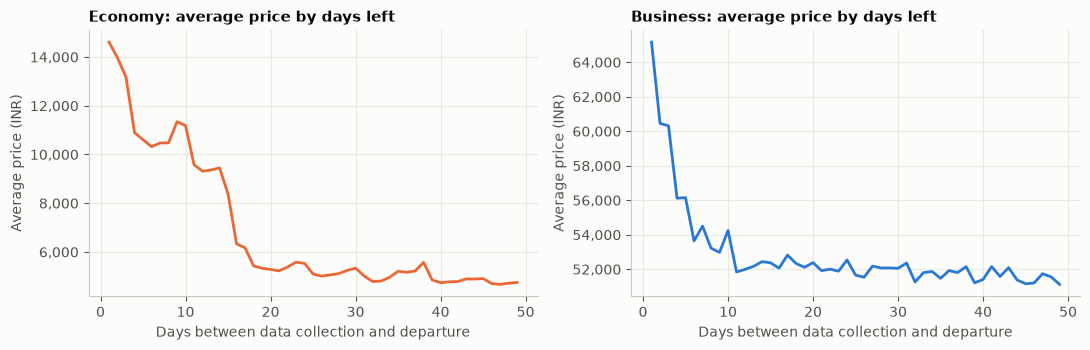

In [11]:
# Price vs. how many days before departure the ticket is bought
mean_by_day = df.groupby(["class", "days_left"])["price"].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, cls in zip(axes, ["Economy", "Business"]):
    d = mean_by_day[mean_by_day["class"] == cls]
    ax.plot(d["days_left"], d["price"], color=CLASS_COLORS[cls])
    ax.set_title(f"{cls}: average price by days left")
    ax.set_xlabel("Days between data collection and departure")
    ax.set_ylabel("Average price (INR)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
save(fig, "fig02_price_vs_days_left")
plt.show()

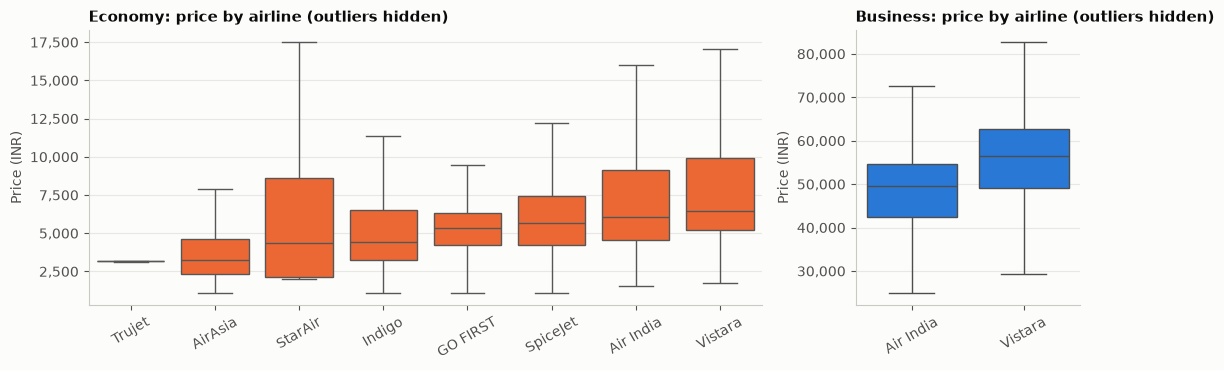

In [12]:
# Price by airline (business class is only offered by two airlines in this data)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1]})
for ax, cls in zip(axes, ["Economy", "Business"]):
    d = df[df["class"] == cls]
    order = d.groupby("airline")["price"].median().sort_values().index
    sns.boxplot(data=d, x="airline", y="price", order=order, color=CLASS_COLORS[cls],
                showfliers=False, linewidth=1, saturation=1, ax=ax)
    ax.set_title(f"{cls}: price by airline (outliers hidden)")
    ax.set_xlabel("")
    ax.set_ylabel("Price (INR)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.tick_params(axis="x", rotation=30)
save(fig, "fig03_price_by_airline")
plt.show()

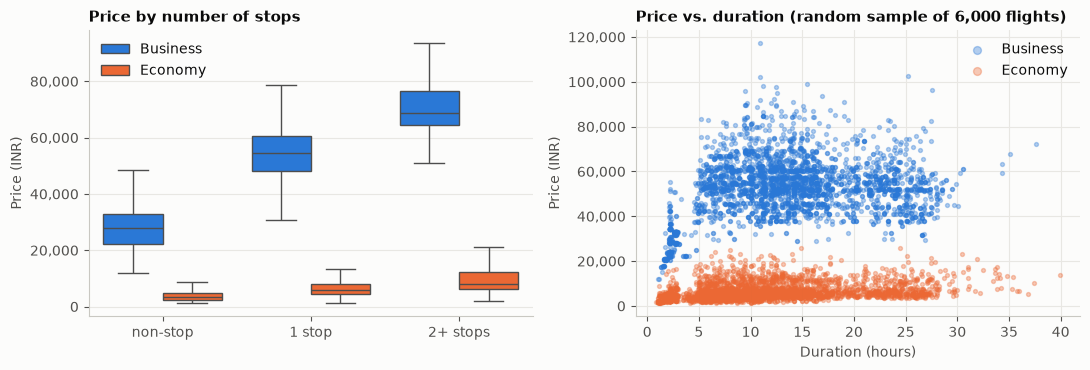

In [13]:
# Price by number of stops and flight duration
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x="stops", y="price", hue="class", palette=CLASS_COLORS,
            showfliers=False, linewidth=1, saturation=1, ax=axes[0])
axes[0].set_title("Price by number of stops")
axes[0].set_xticks([0, 1, 2], ["non-stop", "1 stop", "2+ stops"])
axes[0].set_xlabel("")
axes[0].set_ylabel("Price (INR)")
axes[0].legend(title=None, frameon=False)

sample = df.groupby("class").sample(3000, random_state=RANDOM_STATE)
for cls, d in sample.groupby("class"):
    axes[1].scatter(d["duration_min"] / 60, d["price"], s=8, alpha=0.35, color=CLASS_COLORS[cls], label=cls)
axes[1].set_title("Price vs. duration (random sample of 6,000 flights)")
axes[1].set_xlabel("Duration (hours)")
axes[1].set_ylabel("Price (INR)")
axes[1].legend(frameon=False, markerscale=2)
for ax in axes:
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
save(fig, "fig04_price_by_stops_and_duration")
plt.show()

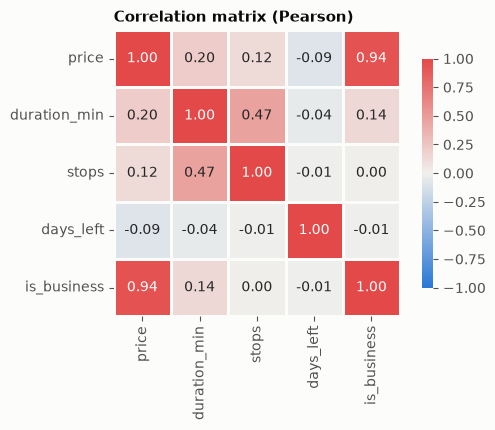

In [14]:
# Correlation between the numeric features and the target
corr_df = df[["price", "duration_min", "stops", "days_left"]].assign(is_business=(df["class"] == "Business").astype(int))
corr = corr_df.corr()
fig, ax = plt.subplots(figsize=(5.6, 4.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, square=True,
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
ax.grid(False)
save(fig, "fig05_correlation")
plt.show()

In [15]:
# Average price by departure period, per class
pivot = df.pivot_table(index="dep_period", columns="class", values="price", aggfunc="mean").reindex(PERIODS)
pivot.round(0)

class,Business,Economy
dep_period,,
Night (00-05),"50,380.00","5,840.00"
Morning (06-11),"53,059.00","6,939.00"
Afternoon (12-16),"50,428.00","6,375.00"
Evening (17-20),"53,341.00","6,589.00"
Late evening (21-23),"51,507.00","5,658.00"


### 1.5 Main observations from the exploration
- **Size and quality:** 300,261 flights. There are no missing values, only 2 exact duplicates and 4 malformed durations,
  which leaves 300,255 rows after cleaning. The main data-quality problem is formatting: price, duration and stops are
  stored as text and had to be parsed.
- **The target has two separate price levels:** the median economy ticket costs about 5,800 INR and the median
  business ticket about 53,200 INR. `class` alone correlates 0.94 with price, so it will dominate every model. The
  harder part is predicting the price *within* each class.
- **Booking lead time has a strong but curved effect:** economy tickets bought 1-3 days before departure cost on
  average around 13,000-14,600 INR, about three times the ~5,000 INR paid when booking more than ~20 days ahead. There is a
  sharp step around 15-17 days. Business prices rise mainly in the last ~10 days. The linear correlation between
  `days_left` and price is only -0.09, because the relationship is non-linear and differs by class.
- **Stops and duration:** within each class, more stops means a higher price (business median ~28,000 INR non-stop
  vs. ~69,000 INR with 2+ stops). Duration correlates with stops (0.47) and only weakly with price (0.20); short
  non-stop flights under 3 hours are the cheapest.
- **Airline:** Vistara and Air India are the most expensive and the only airlines that sell business class.
  AirAsia is the cheapest large carrier. StarAir and Trujet together have only 102 flights.
- **Departure time and weekday** have only small effects (night and late-evening departures are slightly cheaper).
- **Unusual values:** 9 % of the flights take more than 24 hours (up to ~50 hours). These are realistic connections
  with overnight layovers, so they are kept. The most expensive tickets (up to 123,000 INR business / 42,000 INR economy)
  are plausible last-minute fares. They are also kept, because removing them would make the model unrealistic for
  exactly the cases where a price prediction matters most.

## 2. Prepare the data
### 2.1 Feature selection
**Target:** `price` (INR).

**Input features (10):**

| Type | Features |
|---|---|
| Categorical (7) | `airline`, `class`, `from`, `to`, `dep_period`, `arr_period`, `weekday` |
| Numeric (3) | `stops`, `duration_min`, `days_left` |

**Dropped columns and why:**
- `ch_code`: the airline's two-letter code, which carries the same information as `airline`.
- `num_code`: the flight number. It is an identifier with more than 1,000 values; using it would let a model memorise
  individual flights instead of learning general price patterns.
- `date`, `dep_time`, `arr_time`, `time_taken`, `stop`: replaced by the cleaned/engineered columns above.

### 2.2 Missing values, categorical variables and scaling
- **Missing values:** the raw data has no missing values. The only unparseable values were 4 malformed durations;
  those rows were removed (0.001 % of the data), so no imputation is needed.
- **Categorical variables:** Linear Regression needs numbers without a false order, so categories are
  **one-hot encoded**. Random Forest splits on thresholds and handles integer codes well, so it uses
  **ordinal encoding** (one column per feature instead of ~40, which makes training much faster).
- **Feature scaling:** numeric features are **standardised** (mean 0, std 1) for the linear model, because Ridge
  regularisation penalises coefficients and is therefore sensitive to feature scale. Tree-based models are invariant
  to monotonic transformations, so the Random Forest gets **unscaled** features.
- All preprocessing lives inside scikit-learn `Pipeline`s, so encoders and scalers are fitted **only on the
  training folds** during cross-validation. This prevents information from the test set leaking into training.

In [16]:
TARGET = "price"
CATEGORICAL = ["airline", "class", "from", "to", "dep_period", "arr_period", "weekday"]
NUMERIC = ["stops", "duration_min", "days_left"]

X = df[CATEGORICAL + NUMERIC]
y = df[TARGET]
print("X:", X.shape, "| y:", y.shape)

# Preprocessing for the linear model: one-hot encoding + standard scaling
linear_preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])

# Preprocessing for the Random Forest: integer codes for categories, numbers unchanged
tree_preprocess = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
    ("num", "passthrough", NUMERIC),
])

X: (300255, 10) | y: (300255,)


## 3. Create training and test data
80 % of the rows are used for training and 20 % are held out as the test set. The split is **stratified by class**
so that both sets contain the same share of business and economy tickets (otherwise the error metrics could shift
just because one set has more expensive tickets). The test set is not touched again until the final evaluation.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X["class"]
)
print(f"Training set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows")
print("\nShare of each class:")
print(pd.DataFrame({"train": X_train["class"].value_counts(normalize=True),
                    "test": X_test["class"].value_counts(normalize=True)}).round(4))

# The same 5 folds are used for every cross-validation in the notebook
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

Training set: 240,204 rows | Test set: 60,051 rows

Share of each class:
          train  test
class                
Economy    0.69  0.69
Business   0.31  0.31


## 4. Build two regression models
1. **Linear Regression (Ridge):** a linear model with a small L2 penalty on the coefficients. It is fast,
   transparent (one coefficient per feature) and a natural baseline. The starting setting is the scikit-learn default
   `alpha = 1.0`.
2. **Random Forest Regressor:** an ensemble of decision trees trained on bootstrap samples, whose predictions are
   averaged. It captures non-linear effects and interactions (e.g. *days left* matters differently for business than
   for economy) without manual feature engineering. The starting setting is the scikit-learn default
   (`n_estimators = 100`, fully grown trees).

Both models are trained on exactly the same training data.

In [18]:
def evaluate(model, X_eval, y_eval):
    """Return MAE, RMSE and R² for a fitted model."""
    pred = model.predict(X_eval)
    return {"MAE": mean_absolute_error(y_eval, pred),
            "RMSE": root_mean_squared_error(y_eval, pred),
            "R2": r2_score(y_eval, pred)}


ridge_default = Pipeline([("prep", linear_preprocess), ("model", Ridge(alpha=1.0))])
rf_default = Pipeline([("prep", tree_preprocess),
                       ("model", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))])

fit_seconds = {}
for name, model in [("Linear (Ridge)", ridge_default), ("Random Forest", rf_default)]:
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds[name] = time.perf_counter() - start
    print(f"{name:15s} trained in {fit_seconds[name]:6.1f} s")

Linear (Ridge)  trained in    0.4 s
Random Forest   trained in   18.8 s


## 5. Evaluate the models on the test set
- **MAE** (Mean Absolute Error): the average size of an error in rupees, easy to interpret.
- **RMSE** (Root Mean Squared Error): also in rupees, but squares errors first, so large mistakes weigh more.
- **R²**: the share of the variance in ticket prices that the model explains (1 = perfect, 0 = no better than
  always predicting the mean price).

In [19]:
default_results = pd.DataFrame({name: evaluate(m, X_test, y_test)
                                for name, m in [("Linear (Ridge)", ridge_default), ("Random Forest", rf_default)]}).T
default_results["MAE as % of mean price"] = 100 * default_results["MAE"] / y_test.mean()
print(f"Mean ticket price in the test set: {y_test.mean():,.0f} INR (std {y_test.std():,.0f})")
show(default_results)

Mean ticket price in the test set: 20,906 INR (std 22,718)


,MAE,RMSE,R2,MAE as % of mean price
Linear (Ridge),"4,548.9","6,848.6",0.9091,21.8
Random Forest,"1,119.6","2,747.1",0.9854,5.4


In [20]:
# Errors per travel class: the absolute error is naturally larger on expensive business tickets
def per_class_errors(model):
    rows = {}
    for cls in ["Economy", "Business"]:
        mask = X_test["class"] == cls
        m = evaluate(model, X_test[mask], y_test[mask])
        m["mean price"] = y_test[mask].mean()
        m["MAE %"] = 100 * m["MAE"] / m["mean price"]
        rows[cls] = m
    return pd.DataFrame(rows).T


for name, m in [("Linear (Ridge)", ridge_default), ("Random Forest", rf_default)]:
    print(name)
    display(show(per_class_errors(m)))

Linear (Ridge)


,MAE,RMSE,R2,mean price,MAE %
Economy,"2,781.7","3,605.7",0.0810,"6,588.7",42.2
Business,"8,457.5","11,040.2",0.2835,"52,573.4",16.1


Random Forest


,MAE,RMSE,R2,mean price,MAE %
Economy,645.1,"1,427.9",0.8559,"6,588.7",9.8
Business,"2,169.1","4,441.6",0.8840,"52,573.4",4.1


**What the results show (default settings)**
- The **Random Forest is far more accurate**: on average it misses the true price by about 1,120 INR (MAE), compared
  with about 4,550 INR for the linear model. Its RMSE is 2,750 vs. 6,850 INR and its R² is 0.985 vs. 0.909.
- The linear model's R² of 0.91 looks good, but almost all of it comes from separating business from economy.
  **Within each class** the linear model explains only 8 % (economy) and 28 % (business) of the price variance,
  while the Random Forest explains 86 % and 88 %. On economy tickets the linear model is off by 42 % of the average
  fare, compared with 10 % for the Random Forest.
- For both models the RMSE is clearly larger than the MAE, so a minority of tickets (mainly expensive business and
  last-minute fares) produce large errors.

## 6. Improve and tune the models
All tuning uses **5-fold cross-validation on the training data only**; the test set is used once afterwards.
The models are compared with the same folds, and **RMSE** is used to pick the best setting.

### 6.1 Linear Regression (Ridge)
Tuned hyperparameters:
- **Interaction features**: none vs. all pairwise products and squares of the encoded features
  (`PolynomialFeatures(degree=2)`). A plain linear model adds up independent effects, so it cannot express
  that, for example, booking late raises the price differently for business than for economy, or that
  an airline's premium depends on the route. Interactions give the linear model that flexibility.
- `alpha`: regularisation strength (0.01 to 1,000). Larger values shrink the coefficients more, which
  matters more once hundreds of interaction terms are added.
- **Target transformation**: none vs. `log(1 + price)`. Prices are skewed and the effects are likely
  *multiplicative* (business costs roughly x times more, not y rupees more). A linear model on the log
  price can express that; predictions are transformed back to rupees before scoring.

Ridge is cheap to train, so the full training set is used for this grid search (24 combinations x 5 folds).

In [21]:
log_price = FunctionTransformer(np.log1p, inverse_func=np.expm1, check_inverse=False)
interactions = PolynomialFeatures(degree=2, include_bias=False)
ridge_pipe = TransformedTargetRegressor(regressor=Pipeline([
    ("prep", linear_preprocess), ("interactions", "passthrough"), ("model", Ridge())]))

ridge_grid = {
    "regressor__interactions": ["passthrough", interactions],
    "regressor__model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    "transformer": [None, log_price],
}
ridge_search = GridSearchCV(ridge_pipe, ridge_grid, cv=kfold, scoring=SCORING, refit="RMSE", n_jobs=-1)

start = time.perf_counter()
ridge_search.fit(X_train, y_train)
print(f"Grid search finished in {time.perf_counter() - start:.1f} s")

ridge_cv = pd.DataFrame(ridge_search.cv_results_)
ridge_cv["target"] = ridge_cv["param_transformer"].map(lambda t: "price" if t is None else "log(price)")
ridge_cv["interactions"] = ridge_cv["param_regressor__interactions"].map(lambda t: "no" if t == "passthrough" else "yes")
ridge_table = (ridge_cv.assign(alpha=ridge_cv["param_regressor__model__alpha"].astype(float),
                               CV_MAE=-ridge_cv["mean_test_MAE"], CV_RMSE=-ridge_cv["mean_test_RMSE"],
                               CV_R2=ridge_cv["mean_test_R2"])
               [["interactions", "target", "alpha", "CV_MAE", "CV_RMSE", "CV_R2"]].sort_values("CV_RMSE"))
show(ridge_table.reset_index(drop=True), decimals=0)

Grid search finished in 120.9 s


,interactions,target,alpha,CV_MAE,CV_RMSE,CV_R2
0,yes,price,0,"3,267","5,077",0.9499
1,yes,price,10,"3,266","5,077",0.9499
2,yes,price,1,"3,267","5,077",0.9499
3,yes,price,0,"3,267","5,077",0.9499
4,yes,price,100,"3,262","5,077",0.9499
5,yes,price,"1,000","3,239","5,088",0.9497
6,yes,log(price),100,"3,307","5,669",0.9376
7,yes,log(price),0,"3,307","5,670",0.9376
8,yes,log(price),10,"3,307","5,670",0.9376
9,yes,log(price),0,"3,307","5,670",0.9376


In [22]:
ridge_best_params = {"interactions": "no" if ridge_search.best_params_["regressor__interactions"] == "passthrough" else "yes",
                     "alpha": ridge_search.best_params_["regressor__model__alpha"],
                     "target": "price" if ridge_search.best_params_["transformer"] is None else "log(price)"}
print("Best Ridge setting:", ridge_best_params)

# 'Before' = the default setting (no interactions, alpha=1, untransformed target), evaluated with the same 5 folds
ridge_before_cv = ridge_table[(ridge_table["interactions"] == "no") & (ridge_table["target"] == "price")
                             & (ridge_table["alpha"] == 1)].iloc[0]
ridge_after_cv = ridge_table.iloc[0]

Best Ridge setting: {'interactions': 'yes', 'alpha': 0.1, 'target': 'price'}


### 6.2 Random Forest
Tuned hyperparameters:
- `n_estimators`: number of trees (more trees = more stable average, slower).
- `max_depth`: maximum depth of each tree (limits how specific the rules can get).
- `min_samples_leaf`: minimum number of training rows per leaf (higher = smoother predictions, less overfitting).
- `max_features`: share of features considered at each split (lower = more diverse trees).

A full grid would require hundreds of fits on 240,000 rows, so we use **randomized search** (25 random
combinations x 5 folds) on a **random sample of 50,000 training rows**. The default model is cross-validated on the same
sample and folds so that *before* and *after* are directly comparable. The best setting is then retrained on the
full training set.

In [ ]:
X_tune = X_train.sample(50_000, random_state=RANDOM_STATE)
y_tune = y_train.loc[X_tune.index]

rf_pipe = Pipeline([("prep", tree_preprocess), ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))])
rf_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [1.0, 0.7, 0.5, 0.3],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_distributions, n_iter=25, cv=kfold, scoring=SCORING, refit="RMSE",
                               random_state=RANDOM_STATE, n_jobs=-1)

start = time.perf_counter()
rf_search.fit(X_tune, y_tune)
print(f"Randomized search finished in {time.perf_counter() - start:.1f} s")

rf_cv = pd.DataFrame(rf_search.cv_results_)
rf_table = (rf_cv.assign(n_estimators=rf_cv["param_model__n_estimators"], max_depth=rf_cv["param_model__max_depth"],
                         min_samples_leaf=rf_cv["param_model__min_samples_leaf"],
                         max_features=rf_cv["param_model__max_features"],
                         CV_MAE=-rf_cv["mean_test_MAE"], CV_RMSE=-rf_cv["mean_test_RMSE"], CV_R2=rf_cv["mean_test_R2"])
            [["n_estimators", "max_depth", "min_samples_leaf", "max_features", "CV_MAE", "CV_RMSE", "CV_R2"]]
            .sort_values("CV_RMSE"))
show(rf_table.head(10).reset_index(drop=True), decimals=0)

In [ ]:
# 'Before' = default Random Forest, cross-validated on the same 50,000-row sample and the same folds
rf_default_cv = cross_validate(clone(rf_default), X_tune, y_tune, cv=kfold, scoring=SCORING, n_jobs=1)
rf_before_cv = pd.Series({"CV_MAE": -rf_default_cv["test_MAE"].mean(), "CV_RMSE": -rf_default_cv["test_RMSE"].mean(),
                          "CV_R2": rf_default_cv["test_R2"].mean()})
rf_after_cv = rf_table.iloc[0]

rf_best_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
print("Best Random Forest setting:", rf_best_params)

### 6.3 Final models: retrain on the full training set and evaluate on the test set

In [ ]:
# Ridge: GridSearchCV has already refitted the best setting on the full training set
ridge_tuned = ridge_search.best_estimator_

# Random Forest: retrain the best setting on all 240,000 training rows
rf_tuned = clone(rf_search.best_estimator_).set_params(model__n_jobs=-1)
start = time.perf_counter()
rf_tuned.fit(X_train, y_train)
fit_seconds["Random Forest (tuned)"] = time.perf_counter() - start
print(f"Tuned Random Forest trained in {fit_seconds['Random Forest (tuned)']:.1f} s")

tuned_results = pd.DataFrame({name: evaluate(m, X_test, y_test)
                              for name, m in [("Linear (Ridge)", ridge_tuned), ("Random Forest", rf_tuned)]}).T

# Before vs. after tuning: cross-validation scores and test-set scores side by side
comparison = pd.DataFrame({
    ("CV (train)", "RMSE before"): [ridge_before_cv["CV_RMSE"], rf_before_cv["CV_RMSE"]],
    ("CV (train)", "RMSE after"): [ridge_after_cv["CV_RMSE"], rf_after_cv["CV_RMSE"]],
    ("CV (train)", "R² before"): [ridge_before_cv["CV_R2"], rf_before_cv["CV_R2"]],
    ("CV (train)", "R² after"): [ridge_after_cv["CV_R2"], rf_after_cv["CV_R2"]],
    ("Test", "MAE before"): default_results["MAE"].values,
    ("Test", "MAE after"): tuned_results["MAE"].values,
    ("Test", "RMSE before"): default_results["RMSE"].values,
    ("Test", "RMSE after"): tuned_results["RMSE"].values,
    ("Test", "R² before"): default_results["R2"].values,
    ("Test", "R² after"): tuned_results["R2"].values,
}, index=["Linear (Ridge)", "Random Forest"])
show(comparison)

In [ ]:
# Predicted vs. actual price on the test set for the two tuned models
pred_sample = X_test.sample(6000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, [("Linear (Ridge)", ridge_tuned), ("Random Forest", rf_tuned)]):
    pred = model.predict(pred_sample)
    for cls in ["Economy", "Business"]:
        mask = (pred_sample["class"] == cls).values
        ax.scatter(y_test.loc[pred_sample.index][mask], pred[mask], s=6, alpha=0.35,
                   color=CLASS_COLORS[cls], label=cls)
    lim = [0, y_test.max() * 1.02]
    ax.plot(lim, lim, color="#52514e", linewidth=1, linestyle="--", label="Perfect prediction")
    ax.set_title(f"{name} (tuned): R² = {tuned_results.loc[name, 'R2']:.3f}")
    ax.set_xlabel("Actual price (INR)")
    ax.set_ylabel("Predicted price (INR)")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f}k")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f}k")
axes[0].legend(frameon=False, markerscale=3, loc="upper left")
save(fig, "fig06_predicted_vs_actual")
plt.show()

**Effect of tuning**
- **Linear model: clear improvement.** The best setting adds pairwise interaction features, uses `alpha = 10` and
  keeps the untransformed price. Cross-validated RMSE dropped from 6,803 to 5,077 INR (-25 %). On the test set, MAE fell
  from 4,549 to 3,277 INR, RMSE from 6,849 to 5,096 INR, and R² rose from 0.909 to 0.950. The whole gain comes from the
  interactions: `alpha` only changes the results in the 4th decimal, because with 240,000 rows there is little overfitting
  to regularise. The log-price target made RMSE *worse*. It minimises relative errors, which increases the absolute
  errors on expensive business tickets.
- **Random Forest: almost no change.** The default setting was already close to optimal: cross-validated RMSE went from
  3,279 to 3,270 INR (-0.3 %), and test MAE from 1,120 to 1,117 INR, with R² unchanged at 0.985. The best setting
  (200 trees, `max_depth = 30`, `min_samples_leaf = 1`, all features per split) is essentially the default with more
  trees. Every setting that restricted the trees (larger leaves, fewer features per split, shallow trees) did worse,
  so the data is large and consistent enough that deep trees do not overfit badly, and averaging many trees controls the variance.
- *Caveat:* the forest was tuned on a 50,000-row sample to save time. The direction of the result (little regularisation
  is best) is very clear, so it is unlikely to change on the full training set.
- Even after tuning, the linear model's average error is about **3 times larger** than the Random Forest's. In the
  plot, Random Forest predictions lie close to the diagonal for both classes, while the linear model shows a much wider
  spread, especially for business tickets.

## 7. Interpret and compare the results
### 7.1 Feature importance: permutation importance
**Permutation importance** shuffles one feature at a time on the test data and measures how much R² drops.
A large drop means the model relies heavily on that feature. It works for *any* model and on the original
10 features (not the 40 one-hot columns), so the two models can be compared directly.
A random 10,000-row test sample and 5 repetitions are used to keep the computation fast.

In [ ]:
X_pi = X_test.sample(10_000, random_state=RANDOM_STATE)
y_pi = y_test.loc[X_pi.index]

importances = {}
for name, model in [("Linear (Ridge)", ridge_tuned), ("Random Forest", rf_tuned)]:
    pi = permutation_importance(model, X_pi, y_pi, scoring="r2", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
    importances[name] = pd.Series(pi.importances_mean, index=X_pi.columns)
importance_table = pd.DataFrame(importances).sort_values("Random Forest", ascending=False)
importance_table.style.format("{:.4f}")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
order = importance_table["Random Forest"].sort_values().index
for ax, name in zip(axes, ["Linear (Ridge)", "Random Forest"]):
    vals = importance_table.loc[order, name]
    ax.barh(order, vals, color=MODEL_COLORS[name], height=0.6)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8, color="#52514e")
    ax.set_title(f"{name}: drop in R² when shuffled")
    ax.set_xlabel("Mean decrease in R²")
    ax.set_xlim(0, importance_table.values.max() * 1.18)
save(fig, "fig07_permutation_importance")
plt.show()

In [ ]:
# The tuned linear model contains hundreds of interaction terms, which are hard to read one by one.
# The linear model WITHOUT interactions has one coefficient per category / numeric feature, so it is used here.
n_tuned_coef = ridge_tuned.regressor_.named_steps["model"].coef_.size
coef = pd.Series(ridge_default.named_steps["model"].coef_,
                 index=ridge_default.named_steps["prep"].get_feature_names_out())
coef.index = coef.index.str.replace("cat__", "").str.replace("num__", "")
print(f"Tuned linear model: {n_tuned_coef:,} coefficients | main-effects model shown below: {coef.size} coefficients")

# Numeric features were standardised, so their coefficient is the effect of +1 standard deviation;
# dividing by the standard deviation gives the effect per unit (per stop, per minute, per day)
scaler = ridge_default.named_steps["prep"].named_transformers_["num"]
per_unit = pd.Series(coef[NUMERIC].values / scaler.scale_, index=NUMERIC)
print("\nEffect per unit of the numeric features (INR):")
print(per_unit.round(1).to_string())

top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
print("\nLargest coefficients (INR, all other features held constant).")
print("Categories are one-hot encoded without a reference level, so each category is compared with the average category.")
top_coef.round(0).to_frame("coefficient (INR)")

**What the feature importances show**
- **`class` dominates both models.** Shuffling it lowers R² by about 1.7 (more than 1, because random class labels
  make predictions worse than simply predicting the mean price).
- **Random Forest:** after class come `duration_min` (0.14), `airline` (0.06), `from` and `to` (0.05 each) and
  `days_left` (0.03). The forest uses duration non-linearly: combined with route and airline, it effectively identifies specific itineraries.
- **Linear model:** after class come `stops` (0.09), `airline` (0.04) and `days_left` (0.02). Duration matters
  very little, because its relationship with price is not a straight line.
- `weekday` is irrelevant for both models (importance ≈ 0) and could be dropped. Departure/arrival period matter only
  slightly.
- The coefficients of the main-effects linear model agree with the exploration: business costs about 45,000 INR more than
  economy, Vistara is the most expensive airline, each extra stop adds several thousand rupees, and every extra day booked in
  advance lowers the price by a little over 100 INR on average. That average hides the steep rise in the last two weeks,
  which a single linear coefficient cannot represent.

### 7.2 Strengths and weaknesses

| | Linear Regression (Ridge) | Random Forest |
|---|---|---|
| **Accuracy (test, tuned)** | MAE 3,277 · RMSE 5,096 · R² 0.950 | MAE 1,117 · RMSE 2,741 · R² 0.985 |
| **Strengths** | Trains in under a second; small model; the main-effects version is fully transparent (one rupee value per feature); behaves predictably outside the training range | Learns non-linear effects and interactions automatically; best on every metric and within both classes; needs no scaling or interaction features; works well with its default settings |
| **Weaknesses** | Assumes effects simply add up, so it cannot follow the curved `days_left` pattern or class-specific effects without manual feature engineering; even with 945 interaction terms its error is ~3x the forest's; the interaction model is no longer easy to interpret | Slower to train and predict, and the stored model is large (hundreds of deep trees); a "black box" that needs permutation importance to explain; cannot extrapolate beyond prices or feature values seen in training; still has its largest errors on business tickets |

### 7.3 Recommendation
**The Random Forest is recommended** for predicting flight prices on this dataset. After tuning it reduces the test MAE
by 66 % (1,117 vs. 3,277 INR) and the RMSE by 46 % (2,741 vs. 5,096 INR) compared with the best linear model, and it
explains 98.5 % of the price variance. More importantly, it remains accurate *within* each class (R² 0.86 for economy and
0.88 for business, vs. 0.52 and 0.60 for the linear model), so its typical economy error of about 640 INR (~10 % of the fare) is
useful in practice. The linear model is only preferable when a very simple, fully explainable model matters more than accuracy.

*Limitations:* the data only covers Indian domestic flights in February-March 2022, and `days_left` is measured from
a single collection date. The model should therefore be retrained before being used for other periods or markets.

In [ ]:
# Save all numbers needed for the PDF report
results = {
    "n_rows_raw": int(len(raw)), "n_rows_clean": int(len(df)),
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "test_mean_price": float(y_test.mean()), "test_std_price": float(y_test.std()),
    "default_test": default_results.drop(columns="MAE as % of mean price").to_dict(orient="index"),
    "tuned_test": tuned_results.to_dict(orient="index"),
    "per_class_tuned": {name: per_class_errors(m).to_dict(orient="index")
                        for name, m in [("Linear (Ridge)", ridge_tuned), ("Random Forest", rf_tuned)]},
    "ridge_cv": {"before": ridge_before_cv[["CV_MAE", "CV_RMSE", "CV_R2"]].astype(float).to_dict(),
                 "after": ridge_after_cv[["CV_MAE", "CV_RMSE", "CV_R2"]].astype(float).to_dict()},
    "rf_cv": {"before": rf_before_cv.astype(float).to_dict(),
              "after": rf_after_cv[["CV_MAE", "CV_RMSE", "CV_R2"]].astype(float).to_dict()},
    "ridge_best_params": {k: (v if isinstance(v, str) else float(v)) for k, v in ridge_best_params.items()},
    "ridge_n_coef": int(n_tuned_coef),
    "ridge_per_unit": per_unit.to_dict(),
    "ridge_table": ridge_table.reset_index(drop=True).to_dict(orient="records"),
    "rf_best_params": {k: (None if v is None else (v if isinstance(v, str) else float(v))) for k, v in rf_best_params.items()},
    "fit_seconds": fit_seconds,
    "permutation_importance": importance_table.to_dict(),
    "ridge_top_coef": top_coef.to_dict(),
}
with open(RESULTS_DIR / "metrics.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved results/metrics.json")